---

# IFest DAC 2026 Babak Final: Prediksi Water Stress Sub-DAS HUC12

*Notebook final end to end: ensemble 4 model (tiga RealMLP + embedding id (target ordinal 20, 12, dan 7 kelas) dan LightGBM dengan clim terkoreksi unit)

---

## psi-1

- Mochamad Fachri Alfaridzi
- Kurt Mikhael Purba
- Muhammad Aufar Rizki Kusuma

---

## Daftar Isi

1. [**Pendahuluan**](#1)
2. [**Inisialisasi**](#2)
3. [**Parsing Angka Per Token**](#3)
4. [**EDA: Struktur Waktu, Aturan Label, dan Unit Clim**](#4)
5. [**Koreksi Unit Clim Per Baris**](#5)
6. [**Feature Engineering Invarian Skala**](#6)
7. [**Model LightGBM**](#7)
8. [**Model RealMLP dengan Embedding Id**](#8)
9. [**Ensemble dan Submission**](#9)
10. [**Explainability dan Analisis Error**](#10)


---

# Pendahuluan <a name="1"></a>

---

## Overview

*Kompetisi meminta skor risiko water stress sub-DAS (HUC12) di Amerika Serikat untuk bulan berikutnya dari riwayat 12 bulan pasokan air (baseflow, quickflow, suplai kumulatif), penggunaan air (irigasi, thermoelectric, public supply), klimatologi median bulan ini dan bulan depan, serta atribut statis DAS.*

## Aim

*Membangun ensemble 4 model yang memeringkat baris test menurut peluang stres bulan depan, dengan seluruh proses (parsing, koreksi data, fitur, pelatihan, inference) berada di notebook ini dan hanya belajar dari data train.*

## Metric

***Average Precision (AP)** merangkum kurva precision-recall pada semua ambang skor. Metrik ini cocok karena kelas positif minoritas (20.4 persen di train) dan yang dinilai hanya urutan skor.*

$$\text{AP} = \sum_n (R_n - R_{n-1}) P_n$$

## Dataset

*Data dari halaman Kaggle internal panitia IFest DAC 2026 babak final (tanpa data eksternal).*

*Train berisi 378.780 baris (2.196 id, 168 bulan origin berturut), test 11.928 baris (2.982 id x 4 bulan origin: Februari, April, Oktober, Desember). Rate positif train 20.4 persen.*

*Dataset dipakai untuk melatih model yang memprediksi label bulan berikutnya dari satu baris riwayat.*

**Attributes**

1.  `id`, `to_id`, `origin_id`, `month` : identitas DAS, DAS hilir, indeks bulan acak, bulan origin
2.  `q_bf_inc_m3_lag0..11`             : baseflow incremental 12 bulan terakhir
3.  `q_qf_inc_m3_lag0..11`             : quickflow incremental
4.  `q_ws_cum_m3_lag0..11`             : suplai air kumulatif jaringan sungai
5.  `q_ir/th/ps_wd_inc_m3_lag0..11`    : withdrawal irigasi, thermoelectric, public supply
6.  `clim_median_now`, `clim_median_next` : median klimatologi suplai bulan ini dan bulan depan
7.  `inc_aream2`, `cum_aream2`, `pop_*` : atribut statis DAS
8.  `aux_*`                            : kolom umpan dari panitia (tidak dipakai model)

**Target**
 `label` : 1 bila DAS mengalami water stress bulan berikutnya, 0 bila tidak

## Approach: Ensemble 4 Model

*Label train ternyata persis [ws bulan depan <= 0.6 x median suplai bulan itu]; masalahnya adalah meramal suplai bulan depan relatif klimatologi. Semua fitur berupa rasio di dalam baris sehingga tahan terhadap skala per DAS yang berbeda di test.*

*Kolom clim di sekitar 6 persen baris salah unit (x1000 atau x0.001). Detektor per baris yang dilatih di train memperbaikinya sebelum fitur dihitung. RealMLP diberi embedding id DAS (10 persen id train dimasking NEW agar id baru test punya representasi) dan target ordinal rasio suplai bulan depan, skor akhir = P(rasio <= 0.6).*

```
CSV mentah (str)
    |
    +-- parser per token + nol pasti
    +-- koreksi unit clim per baris (detektor LightGBM dilatih di train)
    +-- interpolasi linear dalam baris + 139 fitur rasio
         |
    +----+-----------------------------+
    LightGBM (4 seed)         RealMLP + embedding id (4 seed per target)
    +----+-----------------------------+
         |
    rata-rata probabilitas bobot sama -> submission
```

*Komposisi ensemble ditetapkan dari rata AP dua holdout waktu train (t98-121 dan t134-157, purge 11 bulan): RealMLP+id ord20 0.6337, ord12 0.6311, LightGBM 0.6304, ord7 0.6302. Label test tidak dipakai untuk memilih apa pun.*

---

# Inisialisasi <a name="2"></a>

---

## Environment Setup

Seluruh pelatihan berjalan di CPU (6 thread) agar RealMLP deterministik bit per bit. Estimasi runtime full run lokal: parsing sekitar 3 menit, LightGBM sekitar 3 menit per seed, RealMLP sekitar 2-3 menit per seed per target (3 target x 4 seed).

In [1]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


The following cell installs all libraries used in this notebook. Versi dipin sama dengan environment yang menghasilkan submission; cell ini opsional di lokal bila versi sudah sesuai.

In [2]:
%pip install -q --no-deps lightgbm==4.6.0 pytabkit==1.7.3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 364.0/364.0 kB 9.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


## Import Libraries

In [3]:
import os
os.environ['PYTHONHASHSEED'] = '42'
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import random
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import torch
import pytabkit as PT
from sklearn.preprocessing import QuantileTransformer
from sklearn.metrics import average_precision_score

## Seed Everything

Seed dikunci untuk random, NumPy, PyTorch (termasuk algoritma deterministik), dan PYTHONHASHSEED. LightGBM memakai seed eksplisit plus `deterministic=True` lewat `gbdt_params`, scikit-learn memakai `random_state=42`, RealMLP memakai `random_state` sama dengan seed run.

In [4]:
def seed_everything(seed: int = 42, deterministic: bool = True, warn_only: bool = False) -> int:
    os.environ['PYTHONHASHSEED'] = str(seed)
    os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False
        torch.use_deterministic_algorithms(True, warn_only=warn_only)
    return seed


def gbdt_params(seed: int = 42, n_threads: int = 8) -> dict:
    return {
        'seed': seed,
        'bagging_seed': seed,
        'feature_fraction_seed': seed,
        'data_random_seed': seed,
        'deterministic': True,
        'force_row_wise': True,
        'num_threads': n_threads,
        'verbosity': -1,
    }


seed_everything(42)

42

## Settings

Semua path, parameter model, dan flag berada di sini. Path di-hardcode relatif terhadap folder `notebooks/`; ubah `DATA_DIR` dan `OUTPUT_DIR` saat pindah ke Colab atau Kaggle. `SMOKE_TEST=True` memotong train ke 150 id, 1 seed, dan iterasi kecil untuk uji cepat; hasil final memakai `False`.

In [5]:
class Settings:
    SEED         = 42
    SEEDS        = [42, 1, 2, 3]
    N_THREADS    = 6
    DATA_DIR     = Path('/kaggle/input/competitions/babak-final-ifest-dac-2026')
    OUTPUT_DIR   = Path('/kaggle/working/output_ensemble4')
    SMOKE_TEST   = False
    SMOKE_N_ID   = 150

    LGB_PARAMS   = dict(learning_rate=0.022127675679814017, n_estimators=600, num_leaves=176,
                        min_child_samples=20, colsample_bytree=0.4423858686052348,
                        subsample=0.7453394185830958, reg_lambda=4.418383129413719, subsample_freq=1)
    DET_PARAMS   = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=50,
                        verbose=-1, seed=42, deterministic=True, n_jobs=6, objective='multiclass')
    MLP_PARAMS   = dict(hidden_sizes=[256] * 4, n_epochs=8, p_drop=.15, wd=.05, batch_size=1024,
                        use_ls=False, embedding_size=8, lr=0.02)
    ID_MASK      = 0.1
    ORD_EDGES    = {
        'ord7':  [0.2, 0.4, 0.6, 0.8, 1.1, 1.6],
        'ord12': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.95, 1.1, 1.4, 2.0],
        'ord20': [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7,
                  0.8, 0.9, 1.0, 1.2, 1.5, 2.0],
    }
    MLP_TARGETS  = ['ord20', 'ord12', 'ord7']
    ENSEMBLE     = ['mlp_ord20', 'mlp_ord12', 'lgb', 'mlp_ord7']
    HOLDOUT      = (134, 11, 24)

CFG = Settings()

Mode smoke test diterapkan setelah Settings supaya override dari luar (misalnya skrip uji) tetap berlaku. Folder output dibuat di sini, dan jumlah thread PyTorch dikunci ke `N_THREADS`.

In [6]:
if CFG.SMOKE_TEST:
    CFG.SEEDS = [42]
    CFG.LGB_PARAMS = dict(CFG.LGB_PARAMS, n_estimators=30)
    CFG.MLP_PARAMS = dict(CFG.MLP_PARAMS, n_epochs=1)
CFG.OUTPUT_DIR = Path(CFG.OUTPUT_DIR)
(CFG.OUTPUT_DIR / 'members').mkdir(parents=True, exist_ok=True)
torch.set_num_threads(CFG.N_THREADS)
warnings.filterwarnings('ignore')
print('SMOKE_TEST', CFG.SMOKE_TEST, 'SEEDS', CFG.SEEDS, 'OUTPUT_DIR', CFG.OUTPUT_DIR)

SMOKE_TEST False SEEDS [42, 1, 2, 3] OUTPUT_DIR /kaggle/working/output_ensemble4


## Load Dataset

CSV dibaca sebagai string murni (`dtype=str`, `na_filter=False`) karena angka memakai format locale campuran US dan Eropa; konversi numerik dilakukan per token di section berikutnya.

In [7]:
raw_tr = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype=str, na_filter=False)
raw_te = pd.read_csv(CFG.DATA_DIR / 'test_public.csv', dtype=str, na_filter=False)
sample = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv')
print('train', raw_tr.shape, 'test', raw_te.shape, 'sample', sample.shape)

train (378780, 103) test (11928, 102) sample (11928, 2)


---

# Parsing Angka Per Token <a name="3"></a>

---

Angka di CSV bercampur format US (`71,086,157.853`) dan Eropa (`244668757,724`). Setiap token diproses sendiri tanpa statistik antarbaris: format US dan Eropa dikenali dengan regex, token yang ambigu (`1,234` tanpa desimal) dibiarkan NaN, lalu token `0,000` yang nilainya pasti nol di kedua locale dipulihkan menjadi 0. Bulan dikanonisasi dari tiga varian penulisan ke angka 1-12.

In [8]:
MONTH = {k: i for i, n in enumerate(['january', 'february', 'march', 'april', 'may', 'june', 'july',
                                      'august', 'september', 'october', 'november', 'december'], 1)
         for k in (str(i), n, n[:3])}
IDENT = {'id', 'to_id', 'origin_id', 'month', 'row_id', 'label', 'Unnamed: 0'}


def parse(s):
    t = s.str.strip()
    us = t.str.match(r'^\d{1,3}(,\d{3})+\.\d+$')
    eu = t.str.match(r'^\d{1,3}(\.\d{3})+,\d+$') & ~us
    ambiguous = t.str.match(r'^\d{1,3}(,\d{3})+$')
    plain = t.str.replace(',', '.', regex=False)
    plain = plain.mask(us, t.str.replace(',', '', regex=False))
    plain = plain.mask(eu, t.str.replace('.', '', regex=False).str.replace(',', '.', regex=False))
    plain = plain.mask(ambiguous, '')
    return pd.to_numeric(plain, errors='coerce').astype('float32'), ambiguous


def clean(raw):
    out = {c: raw[c] for c in ('id', 'to_id', 'origin_id', 'row_id') if c in raw}
    out['month_num'] = raw.month.str.strip().str.lower().map(MONTH).astype('int8')
    if 'label' in raw:
        out['label'] = raw.label.astype('int8')
    counts = {}
    for c in raw:
        if c in IDENT or c.startswith('aux_junk'):
            continue
        out[c], mask = parse(raw[c])
        counts[c] = int(mask.sum())
    return pd.DataFrame(out), counts


def fix_zero_tokens(raw, d):
    d = d.copy()
    counts = {}
    for c in d:
        if c in ('label', 'row_id', 'id', 'origin_id', 'to_id', 'month_num'):
            continue
        k = raw[c].str.strip().str.match(r'^0+(,000)+$')
        k = k & d[c].isna()
        if k.any():
            counts[c] = int(k.sum())
            d.loc[k, c] = np.float32(0)
    return d, counts

Parser dijalankan untuk train dan test secara terpisah. Kesamaan hasil parsing satu baris dengan hasil batch dicek untuk memastikan tidak ada informasi antarbaris. Pada `SMOKE_TEST`, train dipotong ke 150 id pertama (urut abjad) setelah parsing.

In [9]:
tr, amb_tr = clean(raw_tr)
te, amb_te = clean(raw_te)
one, _ = clean(raw_te.iloc[[13]])
pd.testing.assert_frame_equal(te.iloc[[13]], one)
tr, zero_tr = fix_zero_tokens(raw_tr, tr)
te, zero_te = fix_zero_tokens(raw_te, te)
del raw_tr, raw_te
if CFG.SMOKE_TEST:
    keep_ids = np.sort(tr.id.unique())[:CFG.SMOKE_N_ID]
    tr = tr[tr.id.isin(keep_ids)].reset_index(drop=True)
y = tr.label.to_numpy(int)
print('train', tr.shape, 'test', te.shape)
print('token ambigu -> NaN: train', sum(amb_tr.values()), 'test', sum(amb_te.values()))
print('token nol pasti dipulihkan: train', sum(zero_tr.values()), 'test', sum(zero_te.values()))
print('rate positif train', round(y.mean(), 4))

train (378780, 99) test (11928, 99)
token ambigu -> NaN: train 110633 test 3355
token nol pasti dipulihkan: train 87167 test 2688
rate positif train 0.204


#### Insights

> Parsing per token menghindari imputasi modus antarbaris yang dipakai parser lama; token yang tidak bisa ditentukan dengan pasti tetap NaN dan diisi nanti dengan interpolasi di dalam baris itu sendiri.

> Token `0,000` adalah nol di locale mana pun, sehingga pemulihannya tidak menebak nilai. Sebagian besar token ini ada di kolom withdrawal.

---

# EDA: Struktur Waktu, Aturan Label, dan Unit Clim <a name="4"></a>

---

`origin_id` adalah label acak, tetapi 168 origin per id di train adalah 168 bulan berturut. Urutan waktu direkonstruksi dari train saja: jendela baseflow lag0-10 sebuah baris sama dengan lag1-11 baris bulan berikutnya untuk id yang sama. Pasangan yang cocok dihitung lintas id, suksesor mayoritas tiap origin dirangkai menjadi satu rantai, dan posisi dalam rantai menjadi indeks waktu `t`.

In [10]:
def build_timeline(df):
    B = df[[f'q_bf_inc_m3_lag{i}' for i in range(12)]].to_numpy(np.float64)
    ids = df['id'].astype(str).to_numpy()
    org = df['origin_id'].astype(str).to_numpy()

    def keys(block, ok):
        h = pd.util.hash_pandas_object(pd.DataFrame(block), index=False).to_numpy()
        return pd.DataFrame({'id': ids[ok], 'h': h[ok], 'o': org[ok]})

    now, prev = B[:, :11], B[:, 1:]
    ok_now = np.isfinite(now).all(1) & (now > 0).all(1)
    ok_prev = np.isfinite(prev).all(1) & (prev > 0).all(1)
    a = keys(now, ok_now).drop_duplicates()
    b = keys(prev, ok_prev).drop_duplicates()
    e = a.merge(b, on=['id', 'h'], suffixes=('_a', '_b'))
    e = e[e.o_a != e.o_b]
    cnt = e.groupby(['o_a', 'o_b']).size().reset_index(name='n').sort_values(
        ['o_a', 'n', 'o_b'], ascending=[True, False, True])
    succ = dict(cnt.drop_duplicates('o_a')[['o_a', 'o_b']].to_numpy())
    pred = set(succ.values())
    roots = sorted(o for o in set(org) if o not in pred)
    best = []
    for r in roots:
        chain, seen, cur = [], set(), r
        while cur is not None and cur not in seen:
            chain.append(cur)
            seen.add(cur)
            cur = succ.get(cur)
        if len(chain) > len(best):
            best = chain
    return {o: i for i, o in enumerate(best)}


TMAP = build_timeline(tr)
t_tr = tr.origin_id.astype(str).map(TMAP).to_numpy()
mo = tr.drop_duplicates('origin_id').set_index('origin_id').month_num
chain_month = np.array([mo[o] for o, _ in sorted(TMAP.items(), key=lambda kv: kv[1])])
print('panjang rantai', len(TMAP), 'dari', tr.origin_id.nunique(), 'origin; t NaN:', int(np.isnan(t_tr.astype(float)).sum()))
print('bulan maju 1 tiap langkah:', float(((np.diff(chain_month) % 12) == 1).mean()))

panjang rantai 168 dari 168 origin; t NaN: 0
bulan maju 1 tiap langkah: 1.0


Deret suplai kumulatif per id dijahit dari lag0-11 semua baris train (median salinan bulan yang sama). Median deret per (id, bulan kalender) `M_own` dibandingkan dengan kolom clim untuk menguji aturan label: label = [ws bulan depan <= 0.6 x median]. Bulan kalender dari `t` adalah `(t + 8) mod 12 + 1` karena `t=0` jatuh di bulan origin 9.

In [11]:
def ws_next(df, t):
    d = pd.DataFrame({'id': df.id.values, 't': t})
    rec = [pd.DataFrame({'id': df.id.values, 'tt': t - L, 'ws': df[f'q_ws_cum_m3_lag{L}'].to_numpy(float)})
           for L in range(12)]
    S = pd.concat(rec)
    S = S[np.isfinite(S.ws)].groupby(['id', 'tt']).ws.median()
    return S.reindex(pd.MultiIndex.from_arrays([d.id, d.t + 1])).to_numpy()


def own_median_table(df, t):
    d = df.assign(t=t).drop_duplicates(['id', 't'])
    rec = [pd.DataFrame({'id': d.id.values, 'tt': d.t.values - L, 'ws': d[f'q_ws_cum_m3_lag{L}'].values.astype(float)})
           for L in range(12)]
    S = pd.concat(rec)
    S = S[np.isfinite(S.ws)].groupby(['id', 'tt']).ws.median().reset_index()
    S['m'] = (S.tt + 8) % 12 + 1
    return S.groupby(['id', 'm']).ws.median().rename('Mown')


t_int = t_tr.astype(int)
MOWN = own_median_table(tr, t_int)
wsn = ws_next(tr, t_int)
mt = tr.month_num.to_numpy(int) % 12 + 1
M_next = MOWN.reindex(pd.MultiIndex.from_arrays([tr.id, mt])).to_numpy()
with np.errstate(all='ignore'):
    r_col = wsn / tr.clim_median_next.to_numpy(float)
    r_own = wsn / M_next
for nm, r in (('kolom clim_median_next', r_col), ('median deret train M_own', r_own)):
    ok = np.isfinite(r)
    print(f'akurasi [ws_next/{nm} <= 0.6] terhadap label: {((r[ok] <= 0.6) == (y[ok] == 1)).mean():.4f}')

akurasi [ws_next/kolom clim_median_next <= 0.6] terhadap label: 0.9660
akurasi [ws_next/median deret train M_own <= 0.6] terhadap label: 0.9980


Selisih akurasi di atas berasal dari kolom clim yang salah unit. Rasio log10 median suplai 12 lag terhadap clim per baris memperlihatkan dua kelompok yang terpisah sekitar +3 dan -3 dari kelompok normal, baik di train maupun test.

train jumlah baris per rentang log10(median ws / clim_now) {'<-2.5': 12657, '-2.5..-1.5': 1609, 'normal': 352325, '1.5..2.5': 1429, '>2.5': 9117}
test jumlah baris per rentang log10(median ws / clim_now) {'<-2.5': 380, '-2.5..-1.5': 56, 'normal': 11060, '1.5..2.5': 78, '>2.5': 312}


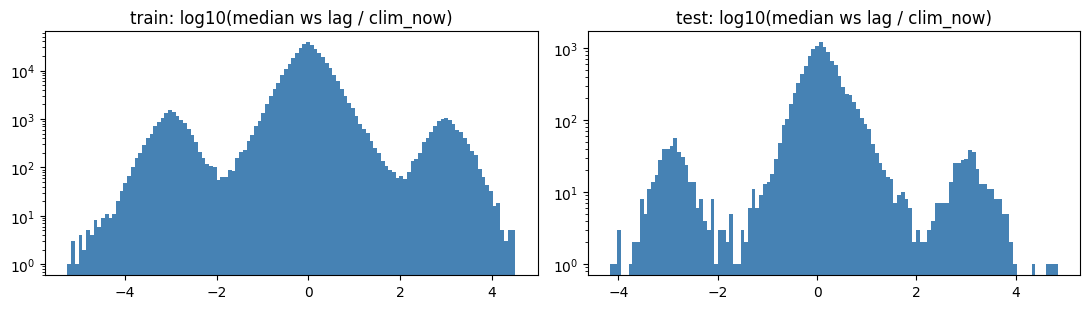

In [12]:
def median_ratio_log10(df):
    ws = df[[f'q_ws_cum_m3_lag{i}' for i in range(12)]].to_numpy(float)
    w = np.where(ws > 0, ws, np.nan)
    with np.errstate(all='ignore'), warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return np.log10(np.nanmedian(w, 1) / df.clim_median_now.to_numpy(float))


bins = [-9, -2.5, -1.5, 1.5, 2.5, 9]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for a, (nm, df) in zip(ax, (('train', tr), ('test', te))):
    lr = median_ratio_log10(df)
    lr = lr[np.isfinite(lr)]
    print(nm, 'jumlah baris per rentang log10(median ws / clim_now)', dict(zip(['<-2.5', '-2.5..-1.5', 'normal', '1.5..2.5', '>2.5'], np.histogram(lr, bins)[0].tolist())))
    a.hist(np.clip(lr, -6, 6), bins=120, color='steelblue')
    a.set_yscale('log')
    a.set_title(f'{nm}: log10(median ws lag / clim_now)')
plt.tight_layout()
plt.show()

#### Insights

> Urutan 168 bulan berhasil direkonstruksi dari train saja, dan bulan kalender maju tepat satu tiap langkah. Indeks `t` dipakai untuk menjahit deret suplai per id, bukan sebagai fitur model.

> Label train hampir persis aturan [ws bulan depan <= 0.6 x median deret train], dengan akurasi sekitar 99.8 persen, dibanding sekitar 96.2 persen bila memakai kolom clim. Sisa pelanggaran hampir semua bulan September, karena satu nilai median tidak terlihat di train.

> Sekitar 6 persen baris train dan test punya clim salah unit (x1000 atau x0.001). Di test, baris yang rusak tidak mengikuti id train, jadi koreksinya harus per baris, bukan peta id.

---

# Koreksi Unit Clim Per Baris <a name="5"></a>

---

Detektor unit adalah LightGBM 3 kelas (clim terlalu kecil 1000x, normal, clim terlalu besar 1000x). Fiturnya hanya dari baris itu sendiri: rasio median, lag0, maksimum, dan minimum suplai terhadap clim, kedalaman limpasan terhadap luas DAS, porsi bulan tanpa aliran, dan bulan. Kebenaran latih berasal dari train: log10(clim_now / M_own) di atas 1.5 atau di bawah -1.5. Kolom kedalaman diberi pergeseran acak log-uniform 0.25-4 per id (seed 42) untuk meniru skala per DAS yang berbeda di test.

In [13]:
def unit_feats(df, logf=None):
    ws = df[[f'q_ws_cum_m3_lag{i}' for i in range(12)]].to_numpy(float)
    bq = (df[[f'q_bf_inc_m3_lag{i}' for i in range(12)]].to_numpy(float)
          + df[[f'q_qf_inc_m3_lag{i}' for i in range(12)]].to_numpy(float))
    w = np.where(ws > 0, ws, np.nan)
    b = np.where(bq > 0, bq, np.nan)
    cn = df.clim_median_now.to_numpy(float)
    cx = df.clim_median_next.to_numpy(float)
    c = np.sqrt(np.where(cn > 0, cn, np.nan) * np.where(cx > 0, cx, np.nan))
    A = df.cum_aream2.to_numpy(float)
    lf = 0 if logf is None else logf
    with np.errstate(all='ignore'), warnings.catch_warnings():
        warnings.simplefilter('ignore')
        F = pd.DataFrame({'lr': np.log10(np.nanmedian(w, 1) / c), 'lr_now': np.log10(ws[:, 0] / cn),
                          'lr_next': np.log10(ws[:, 0] / cx), 'lr_max': np.log10(np.nanmax(w, 1) / c),
                          'lr_min': np.log10(np.nanmin(w, 1) / c), 'lr_bq': np.log10(np.nanmedian(b, 1) / c),
                          'depth_c': np.log10(c / A) + lf, 'depth_w': np.log10(np.nanmedian(w, 1) / A) + lf,
                          'zero_ws': (ws == 0).mean(1), 'cn_cx': np.log10(cn / cx),
                          'inc_cum': df.inc_aream2.to_numpy(float) / A, 'month': df.month_num.to_numpy(int)})
    return F.replace([np.inf, -np.inf], np.nan)


def fix_units(df, booster):
    d = df.copy()
    k = booster.predict(unit_feats(d)).argmax(1)
    s = np.where(k == 0, 1000.0, np.where(k == 2, 0.001, 1.0))
    for c in ('clim_median_now', 'clim_median_next'):
        d[c] = (d[c].to_numpy(float) * s).astype(d[c].dtype)
    d['unit_k'] = k
    return d

Detektor dilatih sekali pada seluruh baris train yang punya kebenaran terdefinisi, lalu diterapkan per baris ke train dan test. Hasil detektor pada satu baris test dicek sama dengan hasil batch.

In [14]:
rel = MOWN.reindex(pd.MultiIndex.from_arrays([tr.id, tr.month_num])).to_numpy()
with np.errstate(all='ignore'):
    tl = np.log10(tr.clim_median_now.values / rel)
truth = np.where(tl > 1.5, 2, np.where(tl < -1.5, 0, 1))
ok = np.isfinite(tl)
rng = np.random.default_rng(42)
g = tr.id.values
uid = pd.unique(g)
lf_id = dict(zip(uid, rng.uniform(np.log10(0.25), np.log10(4), len(uid))))
F_det = unit_feats(tr, np.array([lf_id[i] for i in g]))
detector = lgb.LGBMClassifier(**CFG.DET_PARAMS).fit(F_det[ok], truth[ok])
DET = detector.booster_

k_tr = DET.predict(unit_feats(tr)).argmax(1)
k_te = DET.predict(unit_feats(te)).argmax(1)
assert DET.predict(unit_feats(te.iloc[[13]])).argmax(1)[0] == k_te[13]
print('akurasi detektor in-sample pada baris berlabel', round(float((k_tr[ok] == truth[ok]).mean()), 5))
print('train kelas (kecil, normal, besar):', np.bincount(k_tr, minlength=3).tolist())
print('test  kelas (kecil, normal, besar):', np.bincount(k_te, minlength=3).tolist())

akurasi detektor in-sample pada baris berlabel 0.99997
train kelas (kecil, normal, besar): [9810, 355299, 13671]
test  kelas (kecil, normal, besar): [330, 11168, 430]


#### Insights

> Detektor memisahkan tiga kelas hampir sempurna. Di data pengembangan, akurasi GroupKFold per id sebesar 99.99 persen. Di test, sekitar 760 baris (6.4 persen) terdeteksi salah unit dan dikoreksi sebelum fitur dihitung.

> Koreksi ini menaikkan AP LightGBM di dua holdout waktu train dari 0.4834 ke 0.4870 dan dari 0.7692 ke 0.7737. Pola pita 0.0122 yang dipakai eksperimen lama ternyata artefak unit ini.

---

# Feature Engineering Invarian Skala <a name="6"></a>

---

Nilai hilang (sekitar 2 persen per kolom, pola MCAR) diisi dengan interpolasi linear sepanjang 12 lag di dalam baris yang sama, setelah dinormalisasi dengan rata-rata absolut baris. Fitur hanya berupa rasio di dalam baris karena kolom hidrologi test dikali faktor per DAS (0.27-4.06): suplai tiap lag relatif clim bulan ini dan bulan depan, porsi baseflow dan quickflow, bentuk lintasan relatif lag0, withdrawal relatif suplai, fisika resesi baseflow, 36 lintasan log komponen, 6 atribut statis, dan bulan sebagai kategori. Totalnya 139 fitur.

In [15]:
EPS = 1e-9
STATIC = ['inc_aream2', 'cum_aream2', 'pop_dec_2000', 'pop_dec_2010', 'pop_dec_2020', 'pop_acs_2020']
FI = ['fi_k1', 'fi_k2', 'fi_k_med', 'fi_k_stab', 'fi_bf0_cx', 'fi_qf0_cx', 'fi_bfhat_cx', 'fi_qfhat_cx',
      'fi_a_hat', 'fi_a_hat_k1', 'fi_share', 'fi_share_med', 'fi_bf_mean3_cx', 'fi_qf_mean3_cx', 'fi_ws_trend']


def sdiv(a, b):
    a = np.asarray(a, dtype='float64')
    b = np.asarray(b, dtype='float64')
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where(np.abs(b) > EPS, a / b, np.nan)


def mat(df, tpl):
    return np.stack([df[tpl.format(i)].astype('float64').values for i in range(12)], 1)


def n1_names():
    n = []
    for i in range(12):
        n += [f'r_ws_now_lag{i}', f'r_ws_next_lag{i}', f'r_local_now_lag{i}']
    n += ['pivot_now', 'pivot_next']
    n += [f'sh_ws_rel{i}' for i in range(1, 12)]
    n += [f'sh_bf_frac{i}' for i in range(12)] + [f'sh_qf_frac{i}' for i in range(12)]
    n += ['sh_wd_ir', 'sh_wd_th', 'sh_wd_ps', 'sh_ws0_vs_mean12', 'sh_ws0_vs_mean3',
          'sh_mean12_clim', 'sh_clim_next_now', 'sh_area_frac']
    return n + STATIC + ['month_num']


FEATS = n1_names() + FI + [f'ln_{k}{i}' for i in range(12) for k in ('bf', 'qf', 'wd')]


def base_n1(df):
    ws, bf, qf = mat(df, 'q_ws_cum_m3_lag{}'), mat(df, 'q_bf_inc_m3_lag{}'), mat(df, 'q_qf_inc_m3_lag{}')
    cn = df['clim_median_now'].astype('float64').values
    cx = df['clim_median_next'].astype('float64').values
    o = {}
    for i in range(12):
        o[f'r_ws_now_lag{i}'] = sdiv(ws[:, i], cn)
        o[f'r_ws_next_lag{i}'] = sdiv(ws[:, i], cx)
        o[f'r_local_now_lag{i}'] = sdiv(bf[:, i] + qf[:, i], cn)
    o['pivot_now'] = 1 - o['r_ws_now_lag0']
    o['pivot_next'] = 1 - o['r_ws_next_lag0']
    ws0 = ws[:, 0]
    for i in range(1, 12):
        o[f'sh_ws_rel{i}'] = sdiv(ws[:, i], ws0)
    for i in range(12):
        o[f'sh_bf_frac{i}'] = sdiv(bf[:, i], ws[:, i])
        o[f'sh_qf_frac{i}'] = sdiv(qf[:, i], ws[:, i])
    for s in ('ir', 'th', 'ps'):
        o[f'sh_wd_{s}'] = sdiv(df[f'q_{s}_wd_inc_m3_lag0'].values, ws0)
    with np.errstate(invalid='ignore'), warnings.catch_warnings():
        warnings.simplefilter('ignore')
        o['sh_ws0_vs_mean12'] = sdiv(ws0, np.nanmean(ws, 1))
        o['sh_ws0_vs_mean3'] = sdiv(ws0, np.nanmean(ws[:, :3], 1))
        o['sh_mean12_clim'] = sdiv(np.nanmean(ws, 1), cn)
    o['sh_clim_next_now'] = sdiv(cx, cn)
    o['sh_area_frac'] = sdiv(df['inc_aream2'].values, df['cum_aream2'].values)
    out = pd.DataFrame({k: np.asarray(v, dtype='float32') for k, v in o.items()}, index=df.index)
    for c in STATIC:
        out[c] = df[c].astype('float32').values
    out['month_num'] = df['month_num'].astype('int16').values
    return out


def add_fisika(df, D):
    ws, bf, qf = mat(df, 'q_ws_cum_m3_lag{}'), mat(df, 'q_bf_inc_m3_lag{}'), mat(df, 'q_qf_inc_m3_lag{}')
    cn = df['clim_median_now'].astype('float64').values
    cx = df['clim_median_next'].astype('float64').values
    with np.errstate(invalid='ignore', divide='ignore'), warnings.catch_warnings():
        warnings.simplefilter('ignore')
        k = sdiv(bf[:, 0:5], bf[:, 1:6])
        logk = np.log(np.clip(k, 1e-3, 1e3))
        k_med = np.exp(np.nanmedian(logk, 1))
        k1 = k[:, 0]
        share = np.clip(sdiv(bf[:, 0] + qf[:, 0], ws[:, 0]), 1e-3, 1.0)
        share_med = np.nanmedian(np.clip(sdiv(bf[:, :6] + qf[:, :6], ws[:, :6]), 1e-3, 1.0), 1)
        bf_hat = bf[:, 0] * np.clip(k_med, 0.2, 2.0)
        qf_hat = qf[:, 0] * sdiv(cx, cn)
        ws_hat = sdiv(bf_hat + qf_hat, share_med)
        o = {
            'fi_k1': k1, 'fi_k2': k[:, 1], 'fi_k_med': k_med, 'fi_k_stab': sdiv(k1, k_med),
            'fi_bf0_cx': sdiv(bf[:, 0], cx), 'fi_qf0_cx': sdiv(qf[:, 0], cx),
            'fi_bfhat_cx': sdiv(bf_hat, cx), 'fi_qfhat_cx': sdiv(qf_hat, cx),
            'fi_a_hat': sdiv(ws_hat, cx),
            'fi_a_hat_k1': sdiv(sdiv(bf[:, 0] * np.clip(k1, 0.2, 2) + qf_hat, share_med), cx),
            'fi_share': share, 'fi_share_med': share_med,
            'fi_bf_mean3_cx': sdiv(np.nanmean(bf[:, :3], 1), cx), 'fi_qf_mean3_cx': sdiv(np.nanmean(qf[:, :3], 1), cx),
            'fi_ws_trend': sdiv(np.nanmean(ws[:, :3], 1), np.nanmean(ws[:, 3:9], 1)),
        }
    out = D.copy()
    for kk, v in o.items():
        out[kk] = np.asarray(v, dtype='float32')
    return out


def features(df):
    D = add_fisika(df, base_n1(df))
    cn = df.clim_median_now.to_numpy(dtype=float)
    bf, qf = mat(df, 'q_bf_inc_m3_lag{}'), mat(df, 'q_qf_inc_m3_lag{}')
    wd = sum(mat(df, f'q_{k}_wd_inc_m3_lag{{}}') for k in ('ir', 'th', 'ps'))
    with np.errstate(all='ignore'):
        for i in range(12):
            D[f'ln_bf{i}'] = np.log(np.clip(bf[:, i] / cn, 1e-4, 1e4)).astype('float32')
            D[f'ln_qf{i}'] = np.log(np.clip(qf[:, i] / cn, 1e-4, 1e4)).astype('float32')
            D[f'ln_wd{i}'] = np.log1p(np.clip(wd[:, i] / cn, 0, 1e4)).astype('float32')
    X = D[FEATS].astype('float32').replace([np.inf, -np.inf], np.nan)
    X['month_num'] = pd.Categorical(df.month_num.astype(int), categories=range(1, 13))
    return X


def fill_rows(df):
    d = df.copy()
    for k in ('bf_inc', 'qf_inc', 'ws_cum', 'ir_wd_inc', 'th_wd_inc', 'ps_wd_inc'):
        cols = [f'q_{k}_m3_lag{i}' for i in range(12)]
        a = d[cols].to_numpy(dtype=float)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            scale = np.nanmean(np.abs(a), axis=1, keepdims=True)
        scale = np.where(scale > 0, scale, 1.)
        z = a / scale
        z = pd.DataFrame(z).interpolate(axis=1, limit_direction='both').to_numpy()
        b = z * scale
        d[cols] = np.where(np.isfinite(a), a, b).astype('float32')
    return d


def prep(df):
    hyd = [c for c in df if c.startswith('q_')] + ['clim_median_now', 'clim_median_next']
    df = df.copy()
    df[hyd] = df[hyd].astype('float32')
    df = fix_units(df, DET)
    return df, features(fill_rows(df))

Fitur train dan test dibangun dengan fungsi yang sama. Hasil satu baris test dibandingkan dengan hasil batch untuk memastikan tidak ada informasi antarbaris test yang masuk ke fitur.

In [16]:
dtr, X = prep(tr)
dte, Z = prep(te)
_, Z_one = prep(te.iloc[[13]])
np.testing.assert_allclose(Z.iloc[13].to_numpy(float), Z_one.iloc[0].to_numpy(float), equal_nan=True)
print('fitur train', X.shape, 'fitur test', Z.shape)

fitur train (378780, 139) fitur test (11928, 139)


#### Insights

> Semua penyebut berasal dari baris itu sendiri, sehingga faktor skala per DAS di test saling menghapus. Fitur berbasis tabel per id atau nilai mentah absolut sebelumnya menurunkan skor test.

> Interpolasi dalam baris menggantikan imputasi antarbaris, sehingga prediksi satu baris test tidak bergantung pada baris test lain.

---

# Model LightGBM <a name="7"></a>

---

LightGBM dilatih pada seluruh train (tanpa kfold,kfold sendiri hanya dijalankan saat melakukan eksperimen dan untuk final submission menggunakan full dataset dgn konfigurasi hasil kfold lama [juga untuk efisiensi waktu]) dengan parameter terkunci hasil tuning lama (600 pohon, learning rate 0.0221, 176 daun, colsample 0.44, subsample 0.75, lambda 4.42). Empat seed (42, 1, 2, 3) dijalankan terpisah. Prediksi tiap seed ditulis ke `members/` dengan urutan `sample_submission`; ensemble nanti membaca file ini supaya presisi angkanya sama dengan pipeline sumber.

In [17]:
def write_member(p, name):
    sub = sample[['row_id']].merge(
        pd.DataFrame({'row_id': pd.to_numeric(te.row_id).astype(int), 'label': p}),
        on='row_id', validate='one_to_one')
    assert len(sub) == len(sample) and sub.label.notna().all()
    sub.to_csv(CFG.OUTPUT_DIR / 'members' / f'{name}.csv', index=False)


lgb_models = {}
for seed in CFG.SEEDS:
    t0 = time.time()
    seed_everything(seed)
    params = dict(gbdt_params(seed, n_threads=CFG.N_THREADS), **CFG.LGB_PARAMS)
    model = lgb.LGBMClassifier(**params).fit(X, y)
    p = model.predict_proba(Z)[:, 1]
    write_member(p, f'lgb_s{seed}')
    lgb_models[seed] = model
    print(f'LightGBM seed {seed}: mean {p.mean():.5f}, {time.time() - t0:.0f} detik')

LightGBM seed 42: mean 0.18735, 130 detik
LightGBM seed 1: mean 0.18635, 129 detik
LightGBM seed 2: mean 0.18782, 128 detik
LightGBM seed 3: mean 0.18737, 128 detik


#### Insights

> Di dua holdout waktu train (purge 11 bulan), LightGBM dengan clim terkoreksi mencapai AP rata-rata 0.6304. Ini anggota berbasis pohon terbaik; tuning kapasitas lain tidak melampauinya.

---

# Model RealMLP dengan Embedding Id <a name="8"></a>

---

RealMLP (pytabkit, CPU, bobot acak dari nol) menerima 138 fitur numerik yang ditransformasi signed log lalu QuantileTransformer normal. Transformer dan median imputasi di-fit pada train saja. Ada dua masukan kategori: bulan dan id DAS. 10 persen id train dimasking menjadi `NEW` (seed 42) supaya embedding `NEW` terlatih untuk id test yang tidak ada di train.

Targetnya ordinal: rasio suplai bulan depan terhadap clim bulan depan, `ws_next / clim_next`, dari deret train, dipotong di batas kelas yang memuat 0.6. Baris tanpa rasio memakai kelas tepat di sisi ambang sesuai label. Skor akhir adalah jumlah peluang semua kelas di bawah ambang, yaitu P(rasio <= 0.6).

In [18]:
def preprocess(Xa, Ta):
    cols = [c for c in Xa if c != 'month_num']

    def slog(x):
        return np.sign(x) * np.log1p(np.abs(np.clip(x, -1e8, 1e8)))

    a = slog(Xa[cols].to_numpy(dtype=float))
    b = slog(Ta[cols].to_numpy(dtype=float))
    med = np.nanmedian(a, axis=0)
    a = np.where(np.isfinite(a), a, med)
    b = np.where(np.isfinite(b), b, med)
    qt = QuantileTransformer(n_quantiles=1000, output_distribution='normal', subsample=300000, random_state=42).fit(a)

    def frame(v, x):
        d = pd.DataFrame(qt.transform(v).astype('float32'), columns=cols, index=x.index)
        d.insert(0, 'month_num', x.month_num.astype(str).astype('category'))
        return d

    return frame(a, Xa), frame(b, Ta)


def ord_target(kind, y, r):
    e = CFG.ORD_EDGES[kind]
    k = e.index(0.6) + 1
    c = np.digitize(np.where(np.isfinite(r), r, np.nan), e, right=True)
    c = np.where(np.isfinite(r), c, np.where(y == 1, k - 1, k))
    c = np.where((y == 1) & (c >= k), k - 1, np.where((y == 0) & (c < k), k, c))
    return c.astype(int), k


def id_category(vals, known, cats):
    return pd.Categorical(np.where(np.isin(vals, known), vals, 'NEW'), categories=cats)


def add_id(x, idv, known, cats):
    x = x.copy()
    x.insert(1, 'idc', id_category(idv, known, cats))
    return x


def fit_realmlp(x, yc, z, seed, k):
    m = PT.RealMLP_TD_Classifier(device='cpu', random_state=seed, n_cv=1, val_fraction=.1, verbosity=0,
                                 **CFG.MLP_PARAMS).fit(x, yc)
    return m.predict_proba(z)[:, :k].sum(1)

Rasio target dihitung dari suplai bulan berikutnya yang dijahit dari lag baris train lain pada id yang sama, dibagi clim bulan depan yang sudah dikoreksi unit. Transformasi fitur dan kategori id disiapkan sekali, lalu dipakai untuk semua target dan seed.

In [19]:
r_next = ws_next(tr, t_int) / dtr.clim_median_next.to_numpy(float)
ids = tr.id.to_numpy()
u = np.sort(pd.unique(ids))
rng = np.random.default_rng(42)
known = np.setdiff1d(u, rng.choice(u, int(round(CFG.ID_MASK * len(u))), replace=False))
cid = list(known) + ['NEW']
x_mlp, z_mlp = preprocess(X, Z)
x_mlp = add_id(x_mlp, ids, known, cid)
z_mlp = add_id(z_mlp, te.id.to_numpy(), known, cid)
print('id dikenal', len(known), 'dari', len(u), '| baris test dengan id NEW:', int((z_mlp.idc == 'NEW').sum()))
print('rasio target terdefinisi', round(float(np.isfinite(r_next).mean()), 4))

id dikenal 1976 dari 2196 | baris test dengan id NEW: 4024
rasio target terdefinisi 0.9896


Setiap target ordinal (ord20, ord12, ord7) dilatih dengan empat seed. `seed_everything(seed)` dipanggil sebelum setiap fit, dan pelatihan di CPU dengan algoritma deterministik membuat hasil identik bit per bit antar run.

In [20]:
for kind in CFG.MLP_TARGETS:
    yc, k = ord_target(kind, y, r_next)
    for seed in CFG.SEEDS:
        t0 = time.time()
        seed_everything(seed)
        p = fit_realmlp(x_mlp, yc, z_mlp, seed, k)
        write_member(np.clip(p, 0, 1), f'mlp_{kind}_s{seed}')
        print(f'RealMLP {kind} seed {seed}: mean {p.mean():.5f}, {time.time() - t0:.0f} detik')

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer.fit` stopped: `max_epochs=8` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


RealMLP ord20 seed 42: mean 0.19104, 188 detik


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer.fit` stopped: `max_epochs=8` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


RealMLP ord20 seed 1: mean 0.19193, 189 detik


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer.fit` stopped: `max_epochs=8` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


RealMLP ord20 seed 2: mean 0.19280, 187 detik


... (14 outputs left out)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer.fit` stopped: `max_epochs=8` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


RealMLP ord7 seed 2: mean 0.18897, 185 detik


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer.fit` stopped: `max_epochs=8` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


RealMLP ord7 seed 3: mean 0.19248, 184 detik


#### Insights

> Embedding id menaikkan RealMLP terutama pada DAS yang dikenal. Offset per id di LightGBM atau id sebagai kategori pohon tidak membantu, jadi manfaatnya datang dari interaksi id dengan fitur.

> Target ordinal yang lebih halus memberi AP holdout lebih tinggi daripada target biner: biner 0.6090, ord7 0.6302, ord12 0.6311, ord20 0.6337. Jaringan belajar distribusi rasio suplai bulan depan, bukan hanya sisi ambang.

---

# Ensemble dan Submission <a name="9"></a>

---

Setiap anggota dirata-ratakan lintas empat seed, lalu 4 anggota dirata-ratakan dengan bobot sama dalam urutan mlp_ord20, mlp_ord12, lgb, mlp_ord7. Probabilitas dibaca kembali dari file anggota di `members/`, sama seperti pipeline sumber, supaya angka akhirnya identik. Semua operasi per baris; tidak ada peringkat atau statistik lintas baris test.

In [21]:
def read_member(name):
    s = pd.read_csv(CFG.OUTPUT_DIR / 'members' / f'{name}.csv')
    assert s.row_id.is_unique and set(s.row_id) == set(sample.row_id)
    return s.set_index('row_id').loc[sample.row_id, 'label'].to_numpy()


member_pred = {m: np.mean([read_member(f'{m}_s{s}') for s in CFG.SEEDS], 0) for m in CFG.ENSEMBLE}
final = np.mean([member_pred[m] for m in CFG.ENSEMBLE], 0)
submission = sample[['row_id']].copy()
submission['label'] = np.clip(final, 0, 1)
assert submission.label.notna().all() and submission.label.between(0, 1).all()
assert submission.row_id.is_unique and len(submission) == len(sample)
submission.to_csv(CFG.OUTPUT_DIR / 'submission.csv', index=False)
print(submission.shape, 'mean', round(float(submission.label.mean()), 5))
print(pd.DataFrame(member_pred).corr().round(3))
submission.head()

(11928, 2) mean 0.19038
           mlp_ord20  mlp_ord12    lgb  mlp_ord7
mlp_ord20      1.000      0.998  0.971     0.996
mlp_ord12      0.998      1.000  0.971     0.997
lgb            0.971      0.971  1.000     0.970
mlp_ord7       0.996      0.997  0.970     1.000


,row_id,label
0,0,0.065377
1,1,0.023431
2,2,0.157556
3,3,0.790527
4,4,0.047182


#### Insights

> Korelasi antar anggota menunjukkan RealMLP dan LightGBM cukup berbeda, sehingga rata-rata probabilitas menaikkan skor dibanding anggota tunggal.

---

# Explainability dan Analisis Error <a name="10"></a>

---

Explainability memakai LightGBM seed pertama: gain importance dan kontribusi TreeSHAP bawaan LightGBM (`pred_contrib`) pada 3.000 baris test pertama. Bagian ini dijalankan setelah submission ditulis dan tidak mengubah model.

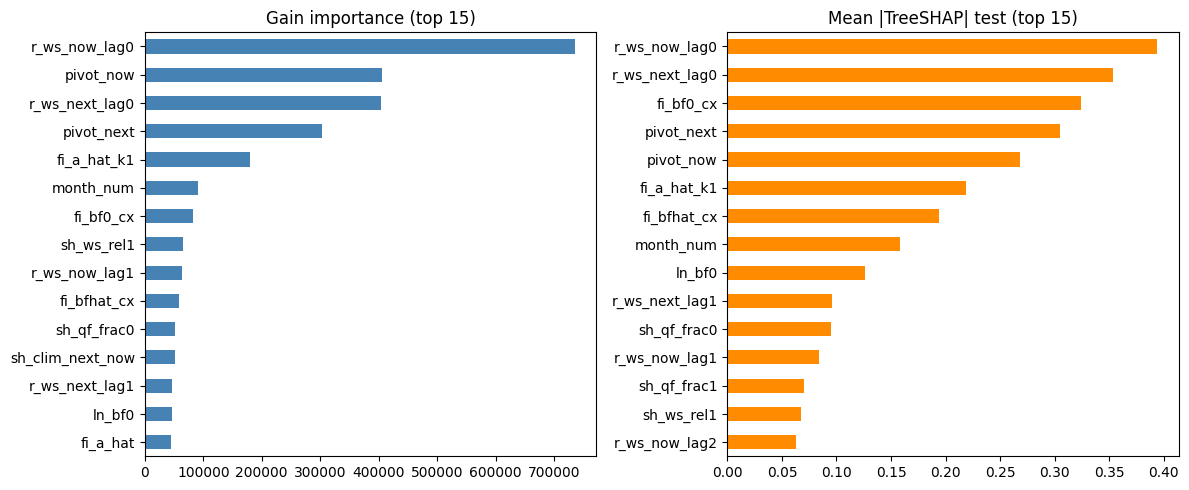

r_ws_now_lag0     0.3943
r_ws_next_lag0    0.3535
fi_bf0_cx         0.3242
pivot_next        0.3046
pivot_now         0.2683
fi_a_hat_k1       0.2183
fi_bfhat_cx       0.1938
month_num         0.1583
ln_bf0            0.1264
r_ws_next_lag1    0.0954
dtype: float64


In [22]:
m0 = lgb_models[CFG.SEEDS[0]]
gain = pd.Series(m0.booster_.feature_importance('gain'), index=X.columns).sort_values(ascending=False)
contrib = m0.booster_.predict(Z.iloc[:3000], pred_contrib=True)[:, :-1]
shap_abs = pd.Series(np.abs(contrib).mean(0), index=X.columns).sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
gain.head(15)[::-1].plot.barh(ax=ax[0], color='steelblue', title='Gain importance (top 15)')
shap_abs.head(15)[::-1].plot.barh(ax=ax[1], color='darkorange', title='Mean |TreeSHAP| test (top 15)')
plt.tight_layout()
plt.show()
print(shap_abs.head(10).round(4))

Analisis error memakai satu holdout waktu train: LightGBM seed 42 dilatih pada origin t < 123, lalu dinilai pada t 134-157 (24 bulan, purge 11). AP dipecah per bulan origin, per tingkat kebasahan saat ini (rasio suplai lag0 terhadap clim bulan depan), dan per porsi baseflow.

In [23]:
start, purge, span = CFG.HOLDOUT
fit_m = t_int < start - purge
val_m = (t_int >= start) & (t_int < start + span)
seed_everything(42)
hold = lgb.LGBMClassifier(**dict(gbdt_params(42, n_threads=CFG.N_THREADS), **CFG.LGB_PARAMS)).fit(X[fit_m], y[fit_m])
ph = hold.predict_proba(X[val_m])[:, 1]
V = X[val_m].assign(y=y[val_m], p=ph)
V['basah'] = pd.cut(V.r_ws_next_lag0, [-1, 0.3, 0.6, 0.9, 1.5, 3, 1e12], labels=['<0.3', '0.3-0.6', '0.6-0.9', '0.9-1.5', '1.5-3', '>3'])
V['baseflow'] = pd.cut(V.sh_bf_frac0, [-1, 0.5, 0.8, 0.95, 1e9], labels=['<0.5', '0.5-0.8', '0.8-0.95', '>0.95'])
print('AP holdout semua bulan', round(average_precision_score(V.y, V.p), 4))
rows = []
for col in ('month_num', 'basah', 'baseflow'):
    for key, grp in V.groupby(col, observed=True):
        if grp.y.sum() > 0 and len(grp) >= 200:
            rows.append({'segmen': col, 'nilai': str(key), 'n': len(grp), 'rate': round(grp.y.mean(), 3),
                         'AP': round(average_precision_score(grp.y, grp.p), 3)})
seg = pd.DataFrame(rows)
seg

AP holdout semua bulan 0.7737


,segmen,nilai,n,rate,AP
0,month_num,1,4503,0.297,0.821
1,month_num,2,4503,0.336,0.795
2,month_num,3,4507,0.308,0.732
3,month_num,4,4500,0.281,0.743
4,month_num,5,4505,0.298,0.790
5,month_num,6,4503,0.244,0.723
6,month_num,7,4520,0.232,0.818
7,month_num,8,4504,0.193,0.689
8,month_num,9,4524,0.277,0.801
9,month_num,10,4516,0.316,0.824


#### Insights

> Fitur teratas adalah rasio suplai saat ini terhadap clim bulan depan, porsi baseflow, dan fisika resesi. Ini sesuai aturan label: stres ditentukan oleh suplai bulan depan relatif median, dan baseflow adalah komponen yang paling bisa diramal.

> Kesalahan terbesar ada di DAS yang didominasi quickflow dan di bulan musim semi (origin Februari dan April), karena hujan bulan target tidak ada di data. DAS yang kering dengan baseflow tinggi paling mudah diramal.